In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
PROJECT_ROOT = Path("../../").resolve()

ANOMALY_PATH = (
    PROJECT_ROOT / "ml" / "outputs" / "anomaly_scores.csv"
)

FEATURE_PATH = (
    PROJECT_ROOT / "ml" / "outputs" / "model_features.csv"
)

AUDIT_PATH = (
    PROJECT_ROOT / "data" / "audit_results.csv"
)

GROUND_TRUTH_PATH = (
    PROJECT_ROOT
    / "data"
    / "ground_truth"
    / "audit_ground_truth.csv"
)

OUTPUT_PATH = (
    PROJECT_ROOT
    / "ml"
    / "outputs"
)

In [3]:
results = pd.read_csv(ANOMALY_PATH)

print("Shape:", results.shape)
print(results.head())

Shape: (85410, 5)
    invoice_id  anomaly_score  is_anomaly ml_risk  rank_percentile
0  INV00000001      -0.078642       False     LOW        52.458728
1  INV00000002      -0.076188       False     LOW        55.109472
2  INV00000003      -0.024538       False  MEDIUM        89.361901
3  INV00000004      -0.104844       False     LOW        17.953401
4  INV00000005      -0.031149       False  MEDIUM        86.928931


In [4]:
features = pd.read_csv(FEATURE_PATH)

print("Shape:", features.shape)
print(features.head())

Shape: (85410, 36)
    invoice_id  billed_amount  calculated_base_charge  \
0  INV00000001        3673.77                 3061.62   
1  INV00000002        1266.90                 1169.05   
2  INV00000003        7602.27                 6749.21   
3  INV00000004        1437.80                 1218.90   
4  INV00000005        4829.40                 3970.11   

   calculated_fuel_surcharge  calculated_accessorial_charges  \
0                     420.48                           100.0   
1                      97.85                             0.0   
2                     853.06                             0.0   
3                     150.57                            50.0   
4                     762.62                             0.0   

   calculated_detention_charge  calculated_subtotal  expected_total  \
0                        91.67              3673.77         3673.77   
1                         0.00              1266.90         1266.90   
2                         0.00          

In [5]:
audit = pd.read_csv(AUDIT_PATH)

print("Shape:", audit.shape)
print(audit.head())
print(audit.columns.tolist())

Shape: (85410, 13)
    invoice_id  shipment_id       load_id  billed_amount audit_status  \
0  INV00000001  SHP00000001  LOAD00000001        3673.77         PASS   
1  INV00000002  SHP00000002  LOAD00000002        1266.90         PASS   
2  INV00000003  SHP00000003  LOAD00000003        7602.27         PASS   
3  INV00000004  SHP00000004  LOAD00000004        1437.80         PASS   
4  INV00000005  SHP00000005  LOAD00000005        4829.40         PASS   

  error_type  overcharge_amount  expected_amount evidence_source  \
0        NaN                0.0          3673.77             NaN   
1        NaN                0.0          1266.90             NaN   
2        NaN                0.0          7602.27             NaN   
3        NaN                0.0          1437.80             NaN   
4        NaN                0.0          4829.40             NaN   

   actual_value  expected_value explanation severity  
0           NaN             NaN         NaN      NaN  
1           NaN        

In [6]:
ground_truth = pd.read_csv(GROUND_TRUTH_PATH)

print("Shape:", ground_truth.shape)
print(ground_truth.head())

Shape: (85410, 5)
    invoice_id  shipment_id  has_injected_error injected_error_type  \
0  INV00000001  SHP00000001               False                 NaN   
1  INV00000002  SHP00000002               False                 NaN   
2  INV00000003  SHP00000003               False                 NaN   
3  INV00000004  SHP00000004               False                 NaN   
4  INV00000005  SHP00000005               False                 NaN   

   injected_error_amount  
0                    0.0  
1                    0.0  
2                    0.0  
3                    0.0  
4                    0.0  


In [7]:
print("Total ML predictions:", len(results))
print("Total features:", len(features))
print("Total audit results:", len(audit))
print("Total ground truth:", len(ground_truth))

Total ML predictions: 85410
Total features: 85410
Total audit results: 85410
Total ground truth: 85410


In [8]:
print("Unique ML invoices:", results["invoice_id"].nunique())
print("Unique audit invoices:", audit["invoice_id"].nunique())
print("Unique ground-truth invoices:", ground_truth["invoice_id"].nunique())

Unique ML invoices: 85410
Unique audit invoices: 85410
Unique ground-truth invoices: 85410


In [9]:
ml_anomalies = results[
    results["is_anomaly"] == True
]

ml_anomaly_count = len(ml_anomalies)

print("ML anomalies:", ml_anomaly_count)
print(
    "ML anomaly percentage:",
    round(ml_anomaly_count / len(results) * 100, 2),
    "%"
)

ML anomalies: 4271
ML anomaly percentage: 5.0 %


In [10]:
rule_failures = audit[
    audit["audit_status"] == "FAIL"
]

rule_failure_count = len(rule_failures)

print("Rule failures:", rule_failure_count)
print(
    "Rule failure percentage:",
    round(rule_failure_count / len(audit) * 100, 2),
    "%"
)

Rule failures: 12811
Rule failure percentage: 15.0 %


In [11]:
audit[
    audit["audit_status"] == "FAIL"
]["severity"].value_counts()

severity
MEDIUM      7196
LOW         3839
HIGH        1497
CRITICAL     279
Name: count, dtype: int64

In [12]:
comparison = results.merge(
    audit[
        [
            "invoice_id",
            "audit_status",
            "severity",
            "overcharge_amount"
        ]
    ],
    on="invoice_id",
    how="inner"
)

print("Comparison shape:", comparison.shape)

Comparison shape: (85410, 8)


In [13]:
coverage = (
    len(comparison) / len(results) * 100
)

print(f"Coverage: {coverage:.2f}%")

Coverage: 100.00%


In [14]:
comparison["ml_anomaly"] = (
    comparison["is_anomaly"] == True
)

comparison["rule_failure"] = (
    comparison["audit_status"] == "FAIL"
)

In [15]:
ml_and_rule = comparison[
    comparison["ml_anomaly"] &
    comparison["rule_failure"]
]

print(
    "ML anomaly + Rule failure:",
    len(ml_and_rule)
)

ML anomaly + Rule failure: 1369


In [16]:
ml_only = comparison[
    comparison["ml_anomaly"] &
    (~comparison["rule_failure"])
]

print(
    "ML anomaly + Rule pass:",
    len(ml_only)
)

ML anomaly + Rule pass: 2902


In [17]:
rule_only = comparison[
    (~comparison["ml_anomaly"]) &
    comparison["rule_failure"]
]

print(
    "ML normal + Rule failure:",
    len(rule_only)
)

ML normal + Rule failure: 11442


In [18]:
both_pass = comparison[
    (~comparison["ml_anomaly"]) &
    (~comparison["rule_failure"])
]

print(
    "ML normal + Rule pass:",
    len(both_pass)
)

ML normal + Rule pass: 69697


In [19]:
category_total = (
    len(ml_and_rule)
    + len(ml_only)
    + len(rule_only)
    + len(both_pass)
)

print("Comparison invoices:", len(comparison))
print("Category total:", category_total)

assert category_total == len(comparison)

print("All invoices accounted for")

Comparison invoices: 85410
Category total: 85410
All invoices accounted for


In [20]:
overlap = pd.DataFrame({
    "category": [
        "ML anomaly + Rule failure",
        "ML anomaly + Rule pass",
        "ML normal + Rule failure",
        "ML normal + Rule pass"
    ],
    "invoice_count": [
        len(ml_and_rule),
        len(ml_only),
        len(rule_only),
        len(both_pass)
    ]
})

overlap["percentage"] = (
    overlap["invoice_count"]
    / len(comparison)
    * 100
)

overlap

,category,invoice_count,percentage
0,ML anomaly + Rule failure,1369,1.602857
1,ML anomaly + Rule pass,2902,3.397729
2,ML normal + Rule failure,11442,13.396558
3,ML normal + Rule pass,69697,81.602857


In [21]:
print("=" * 60)
print("ML vs DETERMINISTIC AUDIT")
print("=" * 60)

print(f"Total invoices              : {len(comparison):,}")
print(f"Rule-based failures        : {rule_failure_count:,}")
print(f"ML anomalies               : {ml_anomaly_count:,}")

print()
print(f"ML + Rule failure          : {len(ml_and_rule):,}")
print(f"ML + Rule pass             : {len(ml_only):,}")
print(f"ML normal + Rule failure   : {len(rule_only):,}")
print(f"ML normal + Rule pass      : {len(both_pass):,}")

ML vs DETERMINISTIC AUDIT
Total invoices              : 85,410
Rule-based failures        : 12,811
ML anomalies               : 4,271

ML + Rule failure          : 1,369
ML + Rule pass             : 2,902
ML normal + Rule failure   : 11,442
ML normal + Rule pass      : 69,697


In [22]:
ground_truth_comparison = results.merge(
    ground_truth,
    on="invoice_id",
    how="inner"
)

print(
    "Ground truth comparison shape:",
    ground_truth_comparison.shape
)

Ground truth comparison shape: (85410, 9)


In [23]:
print(
    ground_truth_comparison[
        "has_injected_error"
    ].value_counts()
)

has_injected_error
False    72599
True     12811
Name: count, dtype: int64


In [24]:
ground_truth_comparison["actual_error"] = (
    ground_truth_comparison["has_injected_error"] == True
)

ground_truth_comparison["ml_anomaly"] = (
    ground_truth_comparison["is_anomaly"] == True
)

In [25]:
true_positive = ground_truth_comparison[
    ground_truth_comparison["actual_error"] &
    ground_truth_comparison["ml_anomaly"]
]

print("True positives:", len(true_positive))

True positives: 1369


In [26]:
false_negative = ground_truth_comparison[
    ground_truth_comparison["actual_error"] &
    (~ground_truth_comparison["ml_anomaly"])
]

print("False negatives:", len(false_negative))

False negatives: 11442


In [27]:
false_positive = ground_truth_comparison[
    (~ground_truth_comparison["actual_error"]) &
    ground_truth_comparison["ml_anomaly"]
]

print("False positives:", len(false_positive))

False positives: 2902


In [28]:
true_negative = ground_truth_comparison[
    (~ground_truth_comparison["actual_error"]) &
    (~ground_truth_comparison["ml_anomaly"])
]

print("True negatives:", len(true_negative))

True negatives: 69697


In [29]:
tp = len(true_positive)
fp = len(false_positive)

precision = (
    tp / (tp + fp)
    if (tp + fp) > 0
    else 0
)

print(f"Precision: {precision:.2%}")

Precision: 32.05%


In [30]:
fn = len(false_negative)

recall = (
    tp / (tp + fn)
    if (tp + fn) > 0
    else 0
)

print(f"Recall: {recall:.2%}")

Recall: 10.69%


In [31]:
f1 = (
    2 * precision * recall / (precision + recall)
    if (precision + recall) > 0
    else 0
)

print(f"F1 score: {f1:.2%}")

F1 score: 16.03%


In [32]:
ground_truth_evaluation = pd.DataFrame({
    "metric": [
        "Total invoices",
        "Known injected errors",
        "ML anomalies",
        "True positives",
        "False positives",
        "False negatives",
        "True negatives",
        "Precision",
        "Recall",
        "F1 score"
    ],
    "value": [
        len(ground_truth_comparison),
        int(
            ground_truth_comparison["actual_error"].sum()
        ),
        int(
            ground_truth_comparison["ml_anomaly"].sum()
        ),
        tp,
        fp,
        fn,
        len(true_negative),
        precision,
        recall,
        f1
    ]
})

ground_truth_evaluation

,metric,value
0,Total invoices,85410.000000
1,Known injected errors,12811.000000
2,ML anomalies,4271.000000
3,True positives,1369.000000
4,False positives,2902.000000
5,False negatives,11442.000000
6,True negatives,69697.000000
7,Precision,0.320534
8,Recall,0.106861
9,F1 score,0.160286


In [33]:
results["anomaly_score"].describe()

count    85410.000000
mean        -0.072593
std          0.037035
min         -0.143670
25%         -0.099598
50%         -0.080898
75%         -0.052863
max          0.113332
Name: anomaly_score, dtype: float64

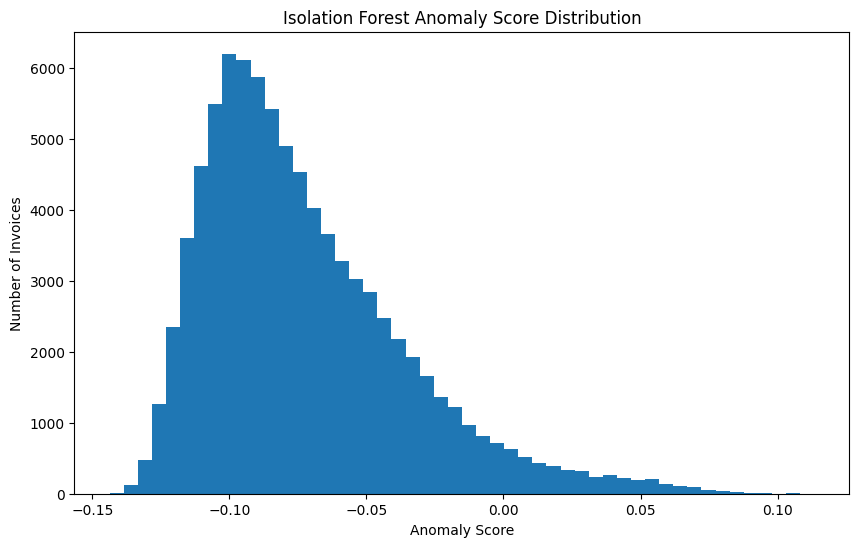

In [34]:
plt.figure(figsize=(10, 6))

plt.hist(
    results["anomaly_score"],
    bins=50
)

plt.xlabel("Anomaly Score")
plt.ylabel("Number of Invoices")
plt.title("Isolation Forest Anomaly Score Distribution")

plt.show()

In [35]:
risk_distribution = (
    results["ml_risk"]
    .value_counts()
)

risk_distribution

ml_risk
LOW       68328
MEDIUM    12811
HIGH       4271
Name: count, dtype: int64

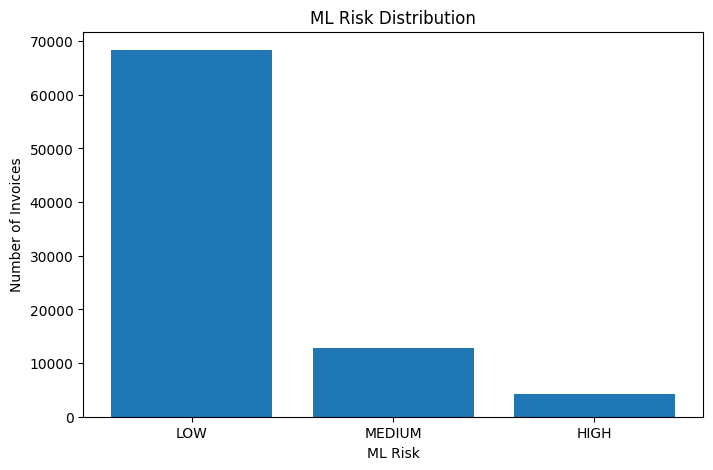

In [36]:
plt.figure(figsize=(8, 5))

plt.bar(
    risk_distribution.index,
    risk_distribution.values
)

plt.xlabel("ML Risk")
plt.ylabel("Number of Invoices")
plt.title("ML Risk Distribution")

plt.show()

In [37]:
top_anomalies = (
    comparison
    .sort_values(
        "anomaly_score",
        ascending=False
    )
    .head(20)
)

top_anomalies[
    [
        "invoice_id",
        "anomaly_score",
        "ml_risk",
        "rank_percentile",
        "audit_status",
        "severity"
    ]
]

,invoice_id,anomaly_score,ml_risk,rank_percentile,audit_status,severity
30458,INV00030459,0.113332,HIGH,100.000000,PASS,NaN
627,INV00000628,0.107630,HIGH,99.998829,FAIL,LOW
66352,INV00066353,0.106127,HIGH,99.997658,FAIL,LOW
4342,INV00004343,0.104655,HIGH,99.996488,PASS,NaN
49517,INV00049518,0.104188,HIGH,99.995317,FAIL,LOW
82927,INV00082928,0.099889,HIGH,99.994146,PASS,NaN
26590,INV00026591,0.099443,HIGH,99.992975,FAIL,LOW
41601,INV00041602,0.097775,HIGH,99.991804,FAIL,MEDIUM
82607,INV00082608,0.097090,HIGH,99.990633,PASS,NaN
27630,INV00027631,0.095644,HIGH,99.989463,PASS,NaN


In [38]:
ml_only[
    [
        "invoice_id",
        "anomaly_score",
        "ml_risk",
        "rank_percentile",
        "audit_status",
        "severity",
        "overcharge_amount"
    ]
].sort_values(
    "anomaly_score",
    ascending=False
).head(30)

,invoice_id,anomaly_score,ml_risk,rank_percentile,audit_status,severity,overcharge_amount
30458,INV00030459,0.113332,HIGH,100.000000,PASS,NaN,0.0
4342,INV00004343,0.104655,HIGH,99.996488,PASS,NaN,0.0
82927,INV00082928,0.099889,HIGH,99.994146,PASS,NaN,0.0
82607,INV00082608,0.097090,HIGH,99.990633,PASS,NaN,0.0
27630,INV00027631,0.095644,HIGH,99.989463,PASS,NaN,0.0
46729,INV00046730,0.095522,HIGH,99.988292,PASS,NaN,0.0
30113,INV00030114,0.095411,HIGH,99.987121,PASS,NaN,0.0
1867,INV00001868,0.094738,HIGH,99.985950,PASS,NaN,0.0
79599,INV00079600,0.093458,HIGH,99.982438,PASS,NaN,0.0
62448,INV00062449,0.091960,HIGH,99.980096,PASS,NaN,0.0


In [39]:
ml_only_with_truth = ml_only.merge(
    ground_truth[
        [
            "invoice_id",
            "has_injected_error",
            "injected_error_type",
            "injected_error_amount"
        ]
    ],
    on="invoice_id",
    how="left"
)

ml_only_with_truth.head()

,invoice_id,anomaly_score,is_anomaly,ml_risk,rank_percentile,audit_status,severity,overcharge_amount,ml_anomaly,rule_failure,has_injected_error,injected_error_type,injected_error_amount
0,INV00000010,0.010928,True,HIGH,96.421965,PASS,NaN,0.0,True,False,False,NaN,0.0
1,INV00000016,0.000396,True,HIGH,95.057956,PASS,NaN,0.0,True,False,False,NaN,0.0
2,INV00000030,0.054188,True,HIGH,99.311556,PASS,NaN,0.0,True,False,False,NaN,0.0
3,INV00000033,0.001952,True,HIGH,95.294462,PASS,NaN,0.0,True,False,False,NaN,0.0
4,INV00000046,0.005639,True,HIGH,95.817820,PASS,NaN,0.0,True,False,False,NaN,0.0


In [40]:
print(
    ml_only_with_truth[
        "has_injected_error"
    ].value_counts(dropna=False)
)

has_injected_error
False    2902
Name: count, dtype: int64


In [41]:
overlap.to_csv(
    OUTPUT_PATH / "ml_evaluation.csv",
    index=False
)

print(
    "Saved:",
    OUTPUT_PATH / "ml_evaluation.csv"
)

Saved: C:\Users\kshit\OneDrive\Desktop\Hack\ml\outputs\ml_evaluation.csv


In [42]:
ground_truth_evaluation.to_csv(
    OUTPUT_PATH / "ground_truth_evaluation.csv",
    index=False
)

print(
    "Saved:",
    OUTPUT_PATH / "ground_truth_evaluation.csv"
)

Saved: C:\Users\kshit\OneDrive\Desktop\Hack\ml\outputs\ground_truth_evaluation.csv


In [43]:
ml_only_with_truth.to_csv(
    OUTPUT_PATH / "ml_only_anomalies.csv",
    index=False
)

print(
    "Saved:",
    OUTPUT_PATH / "ml_only_anomalies.csv"
)

Saved: C:\Users\kshit\OneDrive\Desktop\Hack\ml\outputs\ml_only_anomalies.csv


In [44]:
print("=" * 70)
print("FREIGHT INVOICE ANOMALY DETECTION — FINAL EVALUATION")
print("=" * 70)

print(f"Total invoices             : {len(results):,}")
print(f"Rule-based failures        : {rule_failure_count:,}")
print(f"ML anomalies               : {ml_anomaly_count:,}")

print("\nML vs Rule Engine")
print("-" * 70)

print(f"ML + Rule failure          : {len(ml_and_rule):,}")
print(f"ML + Rule pass             : {len(ml_only):,}")
print(f"ML normal + Rule failure   : {len(rule_only):,}")
print(f"ML normal + Rule pass      : {len(both_pass):,}")

print("\nGround Truth Evaluation")
print("-" * 70)

print(
    f"Known injected errors      : "
    f"{int(ground_truth_comparison['actual_error'].sum()):,}"
)

print(f"True positives             : {tp:,}")
print(f"False positives            : {fp:,}")
print(f"False negatives            : {fn:,}")
print(f"True negatives             : {len(true_negative):,}")

print(f"\nPrecision                  : {precision:.2%}")
print(f"Recall                     : {recall:.2%}")
print(f"F1 Score                   : {f1:.2%}")

FREIGHT INVOICE ANOMALY DETECTION — FINAL EVALUATION
Total invoices             : 85,410
Rule-based failures        : 12,811
ML anomalies               : 4,271

ML vs Rule Engine
----------------------------------------------------------------------
ML + Rule failure          : 1,369
ML + Rule pass             : 2,902
ML normal + Rule failure   : 11,442
ML normal + Rule pass      : 69,697

Ground Truth Evaluation
----------------------------------------------------------------------
Known injected errors      : 12,811
True positives             : 1,369
False positives            : 2,902
False negatives            : 11,442
True negatives             : 69,697

Precision                  : 32.05%
Recall                     : 10.69%
F1 Score                   : 16.03%
